In [ ]:

# 1. Import libraries
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 2. Find the dataset
filename = "StudentPerformanceFactors.csv"

search_paths = [
    Path("."),
    Path("/content"),
    Path("/kaggle/input"),
    Path("/mnt/data")
]

matches = []
for folder in search_paths:
    if folder.exists():
        matches.extend(folder.rglob(filename))

if not matches:
    raise FileNotFoundError(
        "Upload StudentPerformanceFactors.csv to your notebook first."
    )

DATA_PATH = matches[0]
df = pd.read_csv(DATA_PATH)

print("Dataset loaded:", DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded: StudentPerformanceFactors.csv
Dataset shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [ ]:

# Dataset overview
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nDuplicate rows:", df.duplicated().sum())

# Remove exact duplicates
df = df.drop_duplicates().copy()

# Ensure target is numeric
df["Exam_Score"] = pd.to_numeric(df["Exam_Score"], errors="coerce")

# Keep valid target values only
df = df.loc[df["Exam_Score"].between(0, 100)].copy()

print("\nClean dataset shape:", df.shape)
print("\nExam score statistics:")
display(df["Exam_Score"].describe())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence             

,0
Parental_Education_Level,90
Teacher_Quality,78
Distance_from_Home,67
Hours_Studied,0
Access_to_Resources,0
Parental_Involvement,0
Attendance,0
Extracurricular_Activities,0
Motivation_Level,0
Internet_Access,0



Duplicate rows: 0

Clean dataset shape: (6606, 20)

Exam score statistics:


,Exam_Score
count,6606.000000
mean,67.230548
std,3.868502
min,55.000000
25%,65.000000
50%,67.000000
75%,69.000000
max,100.000000


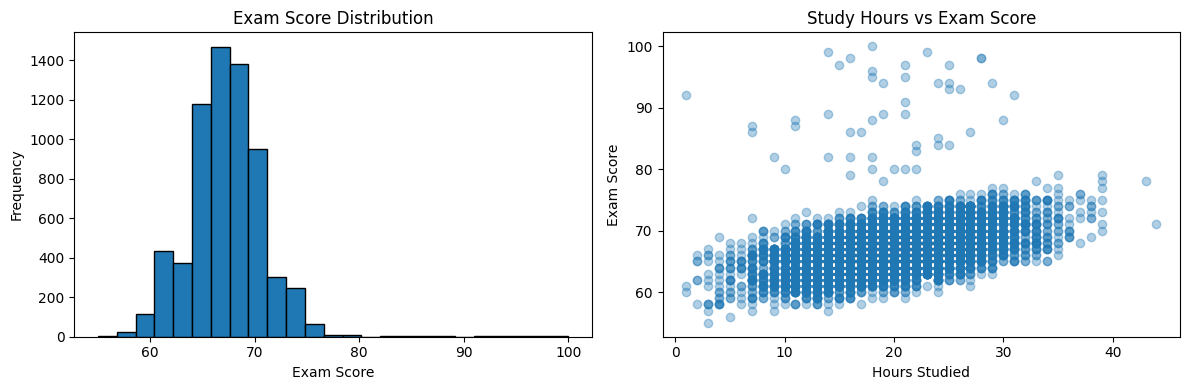

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["Exam_Score"], bins=25, edgecolor="black")
axes[0].set_title("Exam Score Distribution")
axes[0].set_xlabel("Exam Score")
axes[0].set_ylabel("Frequency")

if "Hours_Studied" in df.columns:
    axes[1].scatter(
        df["Hours_Studied"],
        df["Exam_Score"],
        alpha=0.35
    )
    axes[1].set_title("Study Hours vs Exam Score")
    axes[1].set_xlabel("Hours Studied")
    axes[1].set_ylabel("Exam Score")

plt.tight_layout()
plt.show()


In [ ]:

X = df.drop(columns=["Exam_Score"])
y = df["Exam_Score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

print("Train:", X_train.shape)
print("Test:", X_test.shape)


Train: (5284, 19)
Test: (1322, 19)


In [ ]:

# Model 1: Linear Regression using all features
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

# Model 2: Polynomial Regression using numeric features
poly_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False))
])

poly_model = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("num", poly_preprocessor, numeric_cols)
    ], remainder="drop")),
    ("model", Ridge(alpha=10.0))
])

poly_model.fit(X_train, y_train)
poly_pred = poly_model.predict(X_test)

# Evaluation
def evaluate_model(name, y_true, predictions):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        "R2": r2_score(y_true, predictions)
    }

results = pd.DataFrame([
    evaluate_model("Linear Regression - All Features", y_test, linear_pred),
    evaluate_model("Polynomial Regression - Numeric Features", y_test, poly_pred)
])

display(results.round(4))


,Model,MAE,RMSE,R2
0,Linear Regression - All Features,0.4160,1.5213,0.8250
1,Polynomial Regression - Numeric Features,1.2484,2.0497,0.6823


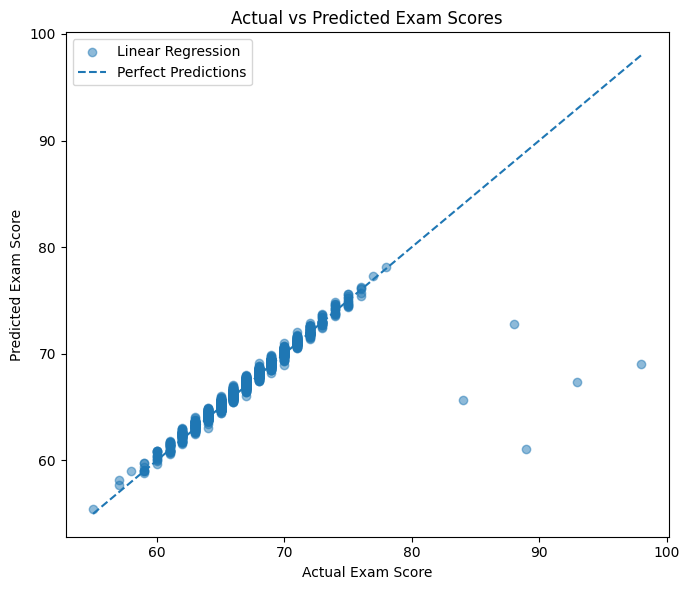

Linear Regression R2: 0.825
Linear Regression MAE: 0.416


In [ ]:

plt.figure(figsize=(7, 6))

plt.scatter(y_test, linear_pred, alpha=0.5, label="Linear Regression")

min_score = min(y_test.min(), linear_pred.min())
max_score = max(y_test.max(), linear_pred.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    linestyle="--",
    label="Perfect Predictions"
)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Actual vs Predicted Exam Scores")
plt.legend()
plt.tight_layout()
plt.show()

print("Linear Regression R2:", round(r2_score(y_test, linear_pred), 4))
print("Linear Regression MAE:", round(mean_absolute_error(y_test, linear_pred), 4))


In [ ]:

from sklearn.base import clone

feature_groups = {
    "Hours Studied Only": [
        "Hours_Studied"
    ],
    "Study + Sleep": [
        "Hours_Studied", "Sleep_Hours"
    ],
    "Study + Attendance": [
        "Hours_Studied", "Attendance"
    ],
    "Study + Sleep + Attendance": [
        "Hours_Studied", "Sleep_Hours", "Attendance"
    ],
    "All Numeric Features": numeric_cols
}

feature_results = []
feature_models = {}

for name, requested_cols in feature_groups.items():
    cols = [c for c in requested_cols if c in X_train.columns]

    if not cols:
        continue

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", LinearRegression())
    ])

    model.fit(X_train[cols], y_train)
    pred = model.predict(X_test[cols])

    feature_models[name] = (model, cols)

    feature_results.append({
        "Feature Set": name,
        "Features Used": len(cols),
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

feature_results = pd.DataFrame(feature_results).sort_values(
    "R2", ascending=False
).reset_index(drop=True)

display(feature_results.round(4))


,Feature Set,Features Used,MAE,RMSE,R2
0,All Numeric Features,6,1.2442,2.0432,0.6843
1,Study + Sleep + Attendance,3,1.4294,2.2357,0.6220
2,Study + Attendance,2,1.4302,2.2367,0.6217
3,Hours Studied Only,1,2.4190,3.1559,0.2469
4,Study + Sleep,2,2.4218,3.1566,0.2465


In [ ]:

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
    GradientBoostingRegressor
)
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

model_candidates = {
    "Linear Regression": LinearRegression(),
    "Ridge alpha=1": Ridge(alpha=1.0),
    "Ridge alpha=10": Ridge(alpha=10.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

candidate_models = {}
candidate_predictions = {}
candidate_rows = []

for name, estimator in model_candidates.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    candidate_models[name] = pipe
    candidate_predictions[name] = pred

    candidate_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

candidate_results = (
    pd.DataFrame(candidate_rows)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(candidate_results.round(4))


,Model,MAE,RMSE,R2
0,Linear Regression,0.4160,1.5213,0.8250
1,Ridge alpha=1,0.4161,1.5213,0.8250
2,Ridge alpha=10,0.4169,1.5213,0.8250
3,Extra Trees,0.9761,1.8913,0.7295
4,Random Forest,1.0248,1.9087,0.7245
5,Gradient Boosting,1.0461,1.9103,0.7241


In [ ]:

# Inspect the largest errors from the current Linear Regression model
error_report = pd.DataFrame(index=X_test.index)

error_report["Actual"] = y_test
error_report["Predicted"] = linear_pred
error_report["Error"] = error_report["Actual"] - error_report["Predicted"]
error_report["Absolute_Error"] = error_report["Error"].abs()

largest_errors = error_report.nlargest(10, "Absolute_Error")

cols_to_show = [
    c for c in [
        "Hours_Studied",
        "Attendance",
        "Previous_Scores",
        "Tutoring_Sessions",
        "Sleep_Hours",
        "Exam_Score"
    ]
    if c in df.columns
]

print("Largest prediction errors:")
display(largest_errors.round(3))

print("Original features for those cases:")
display(
    df.loc[largest_errors.index, cols_to_show]
      .join(largest_errors[["Predicted", "Error", "Absolute_Error"]])
      .round(3)
)

print("Test-set size:", len(y_test))
print(
    "Cases with absolute error > 5:",
    int((error_report["Absolute_Error"] > 5).sum())
)


Largest prediction errors:


,Actual,Predicted,Error,Absolute_Error
6393,98,69.043,28.957,28.957
217,89,61.052,27.948,27.948
4583,93,67.373,25.627,25.627
3932,84,65.661,18.339,18.339
1607,88,72.812,15.188,15.188
5160,68,69.142,-1.142,1.142
2880,57,58.138,-1.138,1.138
1393,71,72.079,-1.079,1.079
5020,63,64.068,-1.068,1.068
2118,65,66.060,-1.060,1.060


Original features for those cases:


,Hours_Studied,Attendance,Previous_Scores,Tutoring_Sessions,Sleep_Hours,Exam_Score,Predicted,Error,Absolute_Error
6393,16,83,92,2,8,98,69.043,28.957,28.957
217,19,70,54,0,7,89,61.052,27.948,27.948
4583,25,73,56,2,7,93,67.373,25.627,25.627
3932,25,66,55,4,7,84,65.661,18.339,18.339
1607,30,98,93,1,9,88,72.812,15.188,15.188
5160,22,74,99,0,5,68,69.142,-1.142,1.142
2880,7,66,68,0,8,57,58.138,-1.138,1.138
1393,21,98,95,0,10,71,72.079,-1.079,1.079
5020,20,65,71,2,8,63,64.068,-1.068,1.068
2118,5,89,76,2,4,65,66.060,-1.060,1.060


Test-set size: 1322
Cases with absolute error > 5: 5


In [ ]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Preserve original data and the original train/test split
df_clean = df.copy()
X_train_new = X_train.copy()
X_test_new = X_test.copy()
y_train_new = y_train.copy()
y_test_new = y_test.copy()

# Identify the five difficult rows from the previous error analysis
worst_indices = largest_errors.nlargest(
    5, "Absolute_Error"
).index

# Remove these rows only in this experimental copy
X_train_new = X_train_new.drop(
    index=X_train_new.index.intersection(worst_indices)
)
y_train_new = y_train_new.loc[X_train_new.index]

X_test_new = X_test_new.drop(
    index=X_test_new.index.intersection(worst_indices)
)
y_test_new = y_test_new.loc[X_test_new.index]

# Fit a fresh copy of the existing preprocessing pipeline
preprocessor_new = clone(preprocessor)

X_train_transformed = preprocessor_new.fit_transform(X_train_new)
X_test_transformed = preprocessor_new.transform(X_test_new)

model_new = LinearRegression()
model_new.fit(X_train_transformed, y_train_new)

pred_new = model_new.predict(X_test_transformed)

print("Experimental results after excluding the five rows")
print("Train rows:", len(y_train_new))
print("Test rows:", len(y_test_new))
print("MAE:", round(mean_absolute_error(y_test_new, pred_new), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_new, pred_new)), 4))
print("R²:", round(r2_score(y_test_new, pred_new), 4))

Experimental results after excluding the five rows
Train rows: 5284
Test rows: 1317
MAE: 0.3294
RMSE: 0.4051
R²: 0.9852


In [ ]:
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Keep the original, complete test set
preprocessor_check = clone(preprocessor)

X_train_check = preprocessor_check.fit_transform(X_train)
X_test_check = preprocessor_check.transform(X_test)

model_check = LinearRegression()
model_check.fit(X_train_check, y_train)

pred_check = model_check.predict(X_test_check)

print("FAIR BASELINE — ORIGINAL TEST SET")
print("Test rows:", len(y_test))
print("MAE:", round(mean_absolute_error(y_test, pred_check), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, pred_check)), 4))
print("R²:", round(r2_score(y_test, pred_check), 4))

FAIR BASELINE — ORIGINAL TEST SET
Test rows: 1322
MAE: 0.416
RMSE: 1.5213
R²: 0.825


In [ ]:
import numpy as np
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

# Reuse the existing preprocessing and preserve the original split
hgb_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

hgb_model.fit(X_train, y_train)
hgb_pred = hgb_model.predict(X_test)

print("HIST GRADIENT BOOSTING — FULL TEST SET")
print("MAE:", round(mean_absolute_error(y_test, hgb_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, hgb_pred)), 4))
print("R²:", round(r2_score(y_test, hgb_pred), 4))

HIST GRADIENT BOOSTING — FULL TEST SET
MAE: 0.6823
RMSE: 1.661
R²: 0.7914


In [ ]:
import numpy as np
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

# Experiment 1: numeric features only
numeric_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LinearRegression())
])

# Use the existing numeric column names
numeric_model = Pipeline([
    ("preprocessor", clone(preprocessor).set_params(
        transformers=[
            ("num", preprocessor.named_transformers_["num"], numeric_cols)
        ],
        remainder="drop"
    )),
    ("model", LinearRegression())
])

numeric_model.fit(X_train[numeric_cols], y_train)
numeric_pred = numeric_model.predict(X_test[numeric_cols])

print("LINEAR REGRESSION — NUMERIC FEATURES ONLY")
print("MAE:", round(mean_absolute_error(y_test, numeric_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, numeric_pred)), 4))
print("R²:", round(r2_score(y_test, numeric_pred), 4))

LINEAR REGRESSION — NUMERIC FEATURES ONLY
MAE: 1.2442
RMSE: 2.0432
R²: 0.6843


In [ ]:
import numpy as np
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

ridge_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)

print("RIDGE REGRESSION — FULL TEST SET")
print("MAE:", round(mean_absolute_error(y_test, ridge_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, ridge_pred)), 4))
print("R²:", round(r2_score(y_test, ridge_pred), 4))

RIDGE REGRESSION — FULL TEST SET
MAE: 0.4161
RMSE: 1.5213
R²: 0.825


In [ ]:
import numpy as np
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ridge_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", Ridge())
])

param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 500, 1000]
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

best_ridge = ridge_search.best_estimator_
ridge_tuned_pred = best_ridge.predict(X_test)

print("TUNED RIDGE — FULL ORIGINAL TEST SET")
print("Best alpha:", ridge_search.best_params_["model__alpha"])
print("CV RMSE:", round(-ridge_search.best_score_, 4))
print("Test MAE:", round(mean_absolute_error(y_test, ridge_tuned_pred), 4))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, ridge_tuned_pred)), 4))
print("Test R²:", round(r2_score(y_test, ridge_tuned_pred), 4))

TUNED RIDGE — FULL ORIGINAL TEST SET
Best alpha: 10
CV RMSE: 2.0839
Test MAE: 0.4169
Test RMSE: 1.5213
Test R²: 0.825


In [ ]:
print("Dataset shape:", df.shape)
print("\nTarget summary:")
print(df["Exam_Score"].describe())

print("\nTarget distribution:")
print(df["Exam_Score"].value_counts().sort_index().tail(15))

print("\nColumns:")
print(df.columns.tolist())

print("\nHighest target correlations (numeric only):")
corr = (
    df.select_dtypes(include="number")
      .corr(numeric_only=True)["Exam_Score"]
      .drop("Exam_Score")
      .sort_values(key=abs, ascending=False)
)
print(corr.head(15))

Dataset shape: (6606, 20)

Target summary:
count    6606.000000
mean       67.230548
std         3.868502
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       100.000000
Name: Exam_Score, dtype: float64

Target distribution:
Exam_Score
85     1
86     4
87     2
88     3
89     3
91     1
92     2
93     2
94     4
95     2
96     1
97     3
98     3
99     2
100    1
Name: count, dtype: int64

Columns:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

Highest target correlations (numeric only):
Attendance           0.582458
Hours_Studied        0.446514
Previous_Scores      0.174461
Tutoring_Sessions    0.15

In [ ]:
# Inspect unusually high exam scores
high_scores = df[df["Exam_Score"] >= 85].copy()

print("Rows with Exam_Score >= 85:", len(high_scores))
print("\nFeature summary for high-score students:")
print(
    high_scores[
        ["Hours_Studied", "Attendance", "Previous_Scores",
         "Tutoring_Sessions", "Exam_Score"]
    ].describe().round(2)
)

print("\nHighest scores and their main features:")
print(
    high_scores.sort_values("Exam_Score", ascending=False)[
        ["Hours_Studied", "Attendance", "Previous_Scores",
         "Tutoring_Sessions", "Exam_Score"]
    ].head(15).to_string(index=False)
)

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

Rows with Exam_Score >= 85: 34

Feature summary for high-score students:
       Hours_Studied  Attendance  Previous_Scores  Tutoring_Sessions  \
count          34.00       34.00            34.00              34.00   
mean           19.65       81.38            75.29               1.38   
std             7.07       11.20            16.95               1.02   
min             1.00       62.00            52.00               0.00   
25%            16.00       70.25            56.50               1.00   
50%            20.00       83.00            76.00               1.00   
75%            25.00       90.00            90.75               2.00   
max            31.00       99.00            98.00               4.00   

       Exam_Score  
count       34.00  
mean        92.35  
std          4.64  
min         85.00  
25%         88.00  
50%         93.00  
75%         96.75  
max        100.00  

Highest scores and their main features:
 Hours_Studied  Attendance  Previous_Scores  Tutoring_Ses

In [ ]:
import numpy as np

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Numeric features: impute, create pairwise interactions, then scale
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler())
])

# Categorical features: impute and one-hot encode
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

feature_preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

interaction_model = Pipeline([
    ("preprocessor", feature_preprocessor),
    ("model", Ridge(alpha=10.0))
])

interaction_model.fit(X_train, y_train)
interaction_pred = interaction_model.predict(X_test)

print("POLYNOMIAL INTERACTIONS + RIDGE")
print("MAE:", round(mean_absolute_error(y_test, interaction_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, interaction_pred)), 4))
print("R²:", round(r2_score(y_test, interaction_pred), 4))

POLYNOMIAL INTERACTIONS + RIDGE
MAE: 0.4305
RMSE: 1.526
R²: 0.8239


In [ ]:
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

cv_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LinearRegression())
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = cross_validate(
    cv_model,
    X,
    y,
    cv=cv,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error"
    },
    n_jobs=-1
)

print("5-FOLD CROSS-VALIDATION")
print("Mean R²:", round(cv_results["test_r2"].mean(), 4))
print("R² std:", round(cv_results["test_r2"].std(), 4))
print("Mean MAE:", round(-cv_results["test_mae"].mean(), 4))
print("Mean RMSE:", round(-cv_results["test_rmse"].mean(), 4))

5-FOLD CROSS-VALIDATION
Mean R²: 0.7347
R² std: 0.0671
Mean MAE: 0.4807
Mean RMSE: 1.984


In [ ]:
print("Preprocessor:")
print(preprocessor)

print("\nNumeric columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)

print("\nMissing values in X_train:")
print(X_train.isnull().sum().sort_values(ascending=False).head(10))

print("\nMissing values in X_test:")
print(X_test.isnull().sum().sort_values(ascending=False).head(10))

print("\nTarget alignment:")
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test: ", X_test.shape,  "| y_test: ", y_test.shape)
print("Train indices aligned:", X_train.index.equals(y_train.index))
print("Test indices aligned: ", X_test.index.equals(y_test.index))

Preprocessor:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Hours_Studied', 'Attendance', 'Sleep_Hours',
                                  'Previous_Scores', 'Tutoring_Sessions',
                                  'Physical_Activity']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Parental_Involvement', 'Access_to_Resources',
                                  'Extracurricular_Activities',
                

In [ ]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

cv = KFold(n_splits=5, shuffle=True, random_state=42)

fold_results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X), start=1):
    X_fold_train = X.iloc[train_idx]
    X_fold_val = X.iloc[val_idx]
    y_fold_train = y.iloc[train_idx]
    y_fold_val = y.iloc[val_idx]

    fold_preprocessor = clone(preprocessor)

    X_fold_train_processed = fold_preprocessor.fit_transform(X_fold_train)
    X_fold_val_processed = fold_preprocessor.transform(X_fold_val)

    from sklearn.linear_model import LinearRegression

    fold_model = LinearRegression()
    fold_model.fit(X_fold_train_processed, y_fold_train)
    fold_pred = fold_model.predict(X_fold_val_processed)

    fold_results.append({
        "Fold": fold,
        "Rows": len(val_idx),
        "MAE": mean_absolute_error(y_fold_val, fold_pred),
        "RMSE": np.sqrt(mean_squared_error(y_fold_val, fold_pred)),
        "R2": r2_score(y_fold_val, fold_pred)
    })

fold_df = pd.DataFrame(fold_results)

print(fold_df.round(4).to_string(index=False))
print("\nMean R²:", round(fold_df["R2"].mean(), 4))
print("Std R²:", round(fold_df["R2"].std(ddof=1), 4))

 Fold  Rows    MAE   RMSE     R2
    1  1322 0.4160 1.5213 0.8250
    2  1321 0.4528 1.8328 0.7658
    3  1321 0.4568 1.8514 0.7538
    4  1321 0.5750 2.5619 0.6247
    5  1321 0.5029 2.1525 0.7041

Mean R²: 0.7347
Std R²: 0.075


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)

target_folds = []

for fold, (_, val_idx) in enumerate(cv.split(X), start=1):
    y_fold = y.iloc[val_idx]

    target_folds.append({
        "Fold": fold,
        "Rows": len(y_fold),
        "Mean score": y_fold.mean(),
        "Std score": y_fold.std(),
        "Min score": y_fold.min(),
        "Max score": y_fold.max(),
        "Scores >= 85": (y_fold >= 85).sum(),
        "Scores >= 90": (y_fold >= 90).sum()
    })

print(pd.DataFrame(target_folds).round(2).to_string(index=False))

 Fold  Rows  Mean score  Std score  Min score  Max score  Scores >= 85  Scores >= 90
    1  1322       67.10       3.64         55         98             4             2
    2  1321       67.15       3.79         57         99             5             4
    3  1321       67.07       3.73         58         98             7             2
    4  1321       67.60       4.18         56         99            10             8
    5  1321       67.24       3.96         57        100             8             5


In [ ]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=3,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring={
            "r2": "r2",
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error"
        },
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Mean R2": scores["test_r2"].mean(),
        "Std R2": scores["test_r2"].std(),
        "Mean MAE": -scores["test_mae"].mean(),
        "Mean RMSE": -scores["test_rmse"].mean()
    })

results_df = pd.DataFrame(results).sort_values(
    "Mean RMSE"
)

print(results_df.round(4).to_string(index=False))

            Model  Mean R2  Std R2  Mean MAE  Mean RMSE
Linear Regression   0.7347  0.0671    0.4807     1.9840
    Random Forest   0.6594  0.0601    1.0828     2.2531


In [24]:

import warnings
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
    VotingRegressor,
    AdaBoostRegressor
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor

warnings.filterwarnings("ignore")

# 1. تجهيز المعالجة داخل Pipeline
numeric_features = list(numeric_cols)
categorical_features = list(categorical_cols)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_all = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# 2. قائمة الموديلات
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10.0),
    "Lasso": Lasso(alpha=0.01, max_iter=10000),
    "ElasticNet": ElasticNet(alpha=0.01, l1_ratio=0.3, max_iter=10000),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, min_samples_leaf=3,
        max_features=0.8, random_state=42, n_jobs=1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200, min_samples_leaf=2,
        max_features=0.8, random_state=42, n_jobs=1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150, learning_rate=0.05,
        max_depth=2, loss="huber", random_state=42
    ),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=150, learning_rate=0.05,
        max_leaf_nodes=15, l2_regularization=1.0,
        random_state=42
    ),
    "KNN": KNeighborsRegressor(n_neighbors=15, weights="distance"),
    "SVR": SVR(C=10, epsilon=0.1),
    "AdaBoost": AdaBoostRegressor(
        n_estimators=100, learning_rate=0.05, random_state=42
    ),
    "Decision Tree": DecisionTreeRegressor(
        min_samples_leaf=10, max_depth=8, random_state=42
    ),
    "Dummy Baseline": DummyRegressor(strategy="mean")
}

# XGBoost اختياري: أضفه فقط لو المكتبة موجودة
try:
    from xgboost import XGBRegressor
    models["XGBoost"] = XGBRegressor(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    )
except ImportError:
    print("XGBoost غير مثبت؛ تم تخطيه.")

# 3. تقييم كل الموديلات بنفس الـ folds
cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, estimator in models.items():
    try:
        pipe = Pipeline([
            ("preprocessor", clone(preprocessor_all)),
            ("model", estimator)
        ])

        scores = cross_validate(
            pipe,
            X,
            y,
            cv=cv,
            scoring={
                "r2": "r2",
                "mae": "neg_mean_absolute_error",
                "rmse": "neg_root_mean_squared_error"
            },
            n_jobs=-1,
            error_score="raise"
        )

        results.append({
            "Model": name,
            "Mean R2": scores["test_r2"].mean(),
            "Std R2": scores["test_r2"].std(),
            "Mean MAE": -scores["test_mae"].mean(),
            "Mean RMSE": -scores["test_rmse"].mean()
        })

        print(f"Finished: {name}")

    except Exception as e:
        print(f"Skipped {name}: {e}")

results_df = pd.DataFrame(results).sort_values(
    "Mean RMSE", ascending=True
).reset_index(drop=True)

print("\n========== FINAL MODEL RANKING ==========")
print(results_df.round(4).to_string(index=False))

print("\n========== BEST MODEL ==========")
if not results_df.empty:
    print(results_df.iloc[0].to_string())

results_df.to_csv("model_comparison_results.csv", index=False)
print("\nSaved: model_comparison_results.csv")


Finished: Linear Regression
Finished: Ridge
Finished: Lasso
Finished: ElasticNet
Finished: Random Forest
Finished: Extra Trees
Finished: Gradient Boosting
Finished: Hist Gradient Boosting
Finished: KNN
Finished: SVR
Finished: AdaBoost
Finished: Decision Tree
Finished: Dummy Baseline
Finished: XGBoost

========== FINAL MODEL RANKING ==========
                 Model  Mean R2  Std R2  Mean MAE  Mean RMSE
                 Ridge   0.7347  0.0671    0.4810     1.9839
     Linear Regression   0.7347  0.0671    0.4807     1.9840
            ElasticNet   0.7344  0.0672    0.4861     1.9848
                 Lasso   0.7341  0.0672    0.4918     1.9863
                   SVR   0.7293  0.0696    0.5111     2.0037
Hist Gradient Boosting   0.7013  0.0664    0.8112     2.1077
               XGBoost   0.6711  0.0657    1.0116     2.2130
           Extra Trees   0.6667  0.0608    1.0302     2.2285
         Random Forest   0.6585  0.0599    1.0864     2.2561
     Gradient Boosting   0.6494  0.0635    1.

In [25]:

import joblib
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.base import clone
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# استخدام تقسيم التدريب والاختبار الأصلي دون حذف أي صفوف
final_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", Ridge(alpha=10.0))
])

final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("=" * 45)
print("STUDENTSCORE AI — FINAL MODEL")
print("=" * 45)
print("Model: Ridge Regression")
print(f"Training rows: {len(X_train)}")
print(f"Testing rows:  {len(X_test)}")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f} ({r2 * 100:.2f}%)")

joblib.dump(final_model, "studentscore_ridge_model.joblib")
print("\nModel saved: studentscore_ridge_model.joblib")


STUDENTSCORE AI — FINAL MODEL
Model: Ridge Regression
Training rows: 5284
Testing rows:  1322
MAE:  0.4169
RMSE: 1.5213
R²:   0.8250 (82.50%)

Model saved: studentscore_ridge_model.joblib


In [26]:
import joblib
import os

model_path = "studentscore_ridge_model.joblib"

assert os.path.exists(model_path), "Model file not found!"

loaded_model = joblib.load(model_path)

sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)[0]
actual = y_test.iloc[0]

print("Model loaded successfully")
print(f"Actual Exam Score: {actual:.2f}")
print(f"Predicted Exam Score: {prediction:.2f}")

Model loaded successfully
Actual Exam Score: 66.00
Predicted Exam Score: 66.02


In [27]:
import joblib
from google.colab import files

joblib.dump(
    loaded_model,
    "studentscore_ridge_model.joblib"
)

files.download("studentscore_ridge_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>